<a name="top" id="top"></a>


**Big idea of this notebook:** a digital image is just a grid (matrix) of numbers called *pixels*.
Every operation we do here — brightening, adding contrast, removing noise, finding edges, cutting out a tumour,
measuring its size — is nothing more than **doing arithmetic on that grid of numbers**.

We use real medical-style images (an MRI scan with a tumour, a noisy lung X-ray) and end by turning
one image into **13 numbers (features)** that a normal machine-learning model could use.

---

### 📚 Table of Contents
1. [Setup — import the libraries](#s1)
2. [Load the images from Google Drive](#s2)
3. [Understand the image as a NumPy array](#s3)
4. [Point operations — brightness, contrast, log, negative](#s4)
5. [Histograms and histogram equalization](#s5)
6. [Spatial filtering with kernels (convolution)](#s6)
7. [Segmentation by thresholding](#s7)
8. [Morphological operations (opening)](#s8)
9. [Manual feature extraction (to solve it via an ML problem)](#s9)
10. [Texture (intensity) features of the tumour](#s10)
11. [Build the feature vector → a dataset for ML](#s11)
12. [Summary and key takeaways](#s12)

<a name="s1" id="s1"></a>

## 1. Setup — import the libraries

[⬆ Back to top](#top)

**What this section does:** We load the four Python libraries used everywhere in this notebook and print the OpenCV version.

In [16]:
# Import OpenCV (cv2), pandas, NumPy and Matplotlib.
#  cv2 reads/processes images, NumPy does the maths on the pixel grid,
#       Matplotlib draws images and plots, pandas shows our final features as a neat table.
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Print the installed OpenCV version.
#  Function names/arguments sometimes change between versions; knowing the version helps debugging.
cv2.__version__

'5.0.0'

<a name="s2" id="s2"></a>

## 2. Load the images from Google Drive

[⬆ Back to top](#top)

**What this section does:** Colab cannot see files on your laptop. So we **mount** (connect) Google Drive, point to the
`open_cv_images` folder and read the first image (*cameraman*). We also set up `cv2_imshow`,
the Colab-safe way to display an image.

In [18]:
# Upgrade gdown to prevent Google Drive API bugs
!pip install --upgrade gdown

In [19]:
# Dataset link for the images used in this notebook
#  Participants need the same images in their own Drive before running the notebook.
# Dataset link
# https://drive.google.com/drive/folders/1_iUEkqVkc5FE_OLf2EY-flZ_7yXlMc7u?usp=sharing

# This script was developed on Google Colab. Some minor changes are required to execute it on a local machine.

In [20]:
# Mount Google Drive (on Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
MOUNT_DIR = '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/'

In [22]:
# # 1. Upgrade gdown to prevent Google Drive API bugs
# !pip install --upgrade gdown

import os
import gdown
from google.colab import drive

# # 2. Mount your personal Google Drive to the Colab environment
# # This will prompt you for authorization to access your Drive files
# drive.mount('/content/drive')

# 3. Define the shared folder URL and your target destination path
folder_url = 'https://drive.google.com/drive/folders/1_iUEkqVkc5FE_OLf2EY-flZ_7yXlMc7u?usp=sharing'

# 4. Create the destination folder automatically if it doesn't already exist
os.makedirs(MOUNT_DIR, exist_ok=True)

# 5. Download the shared folder contents into your specified folder
# The 'output' parameter explicitly directs gdown where to save the files
gdown.download_folder(url=folder_url, output=MOUNT_DIR, quiet=False, use_cookies=False)

Processing file 1l9UHFT6s1BNprZj6Mg8psE4gQDlnZZdU 3_nod.jpg
Processing file 1EH7FfyYpNrxpjV3xaoD1VNvVv8Z6qUsV ballons.bmp
Processing file 1wLWYH-NuHvw9R_4pS5KJlF2XOtMm2-iT cameraman.png
Processing file 1atBYKFcv4qAvkqBbtnGAxGN5ou1XwdXs Image_For_Edge_Detection3.jpg
Processing file 1_v11ocXdRrXgNd37sU1bAF8UKZ_LYc9y leena.png
Processing file 1fA3l1K2VEgM71_cCdhDUGO9aXFrKyJZ9 low_contrast_fruit_basket.jpg
Processing file 1h8IVkdb2ko99HcPIbLGXYA3tRe2Rbq_G lung_img.jpg
Processing file 11-OU6a2EZ8SrjASjBHmS1MFYSlTvgV6o mri_tumor1.jpg
Processing file 1KPLKVT8kqxd1tawaDpHrYuCs7c-gmFW5 noisy_lung.jpg
Processing file 19TNs8Ya9IlXGrdpFT5mAgGyyFt6PYh1O opencv.png
Processing file 1LIm19fQBKmzlYvL2eEHwHfnHvmJO8H5a statue.png


Retrieving folder contents
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1l9UHFT6s1BNprZj6Mg8psE4gQDlnZZdU
To: /content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/3_nod.jpg
100%|██████████| 21.3k/21.3k [00:00<00:00, 23.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1EH7FfyYpNrxpjV3xaoD1VNvVv8Z6qUsV
To: /content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/ballons.bmp
100%|██████████| 15.0k/15.0k [00:00<00:00, 24.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1wLWYH-NuHvw9R_4pS5KJlF2XOtMm2-iT
To: /content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/cameraman.png
100%|██████████| 38.8k/38.8k [00:00<00:00, 42.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1atBYKFcv4qAvkqBbtnGAxGN5ou1XwdXs
To: /content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/Image_For_Edge_Detection3.jpg
100%|██

['/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/3_nod.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/ballons.bmp',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/cameraman.png',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/Image_For_Edge_Detection3.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/leena.png',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/low_contrast_fruit_basket.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/lung_img.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/mri_tumor1.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/noisy_lung.jpg',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/opencv.png',
 '/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/statue.png']

In [23]:
IMG_DIR = MOUNT_DIR + 'open_cv_images/'

In [24]:
# Read cameraman.png and print its shape (rows, columns, channels).
#  cv2.imread turns the file into a NumPy array. By default it ALWAYS returns 3 channels (B, G, R),
#       even for a grey image — that is why we see 3 as the last number.
#loading the file from content drive location

img_path = IMG_DIR + 'cameraman.png'
print(img_path)

img = cv2.imread(IMG_DIR + 'cameraman.png')
img.shape

/content/drive/MyDrive/GL/S1_Images_Processing_OpenCV/open_cv_images/cameraman.png


(256, 256, 3)

In [25]:
# Get a function that can display an image inside the notebook.
#  cv2.imshow() opens a separate desktop window — Colab disables it because it crashes the notebook.
#       Colab gives cv2_imshow() instead (it converts BGR -> RGB and shows the picture in the cell).
try:
    from google.colab.patches import cv2_imshow
    print("On colab")
except ImportError:
    from IPython.display import display
    from PIL import Image
    def cv2_imshow(a):                       # same logic as Colab's version
        a = a.clip(0, 255).astype('uint8')   # pixel values must be whole numbers 0..255
        if a.ndim == 3:                      # colour image: OpenCV stores B,G,R -> convert to R,G,B
            a = cv2.cvtColor(a, cv2.COLOR_BGRA2RGBA if a.shape[2] == 4 else cv2.COLOR_BGR2RGB)
        display(Image.fromarray(a))

# cv2.imshow('screen1',img)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
# the above three lines are for displaying an image on a local machine using OpenCV (they open a window)

On colab


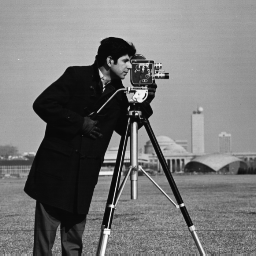

In [26]:
# Show the cameraman image.
#  Always LOOK at the data first — it confirms the file loaded correctly.
cv2_imshow(img)

In [27]:
print(img)

[[[156 156 156]
  [159 159 159]
  [158 158 158]
  ...
  [151 151 151]
  [152 152 152]
  [152 152 152]]

 [[160 160 160]
  [154 154 154]
  [157 157 157]
  ...
  [154 154 154]
  [155 155 155]
  [153 153 153]]

 [[156 156 156]
  [159 159 159]
  [158 158 158]
  ...
  [151 151 151]
  [152 152 152]
  [152 152 152]]

 ...

 [[114 114 114]
  [132 132 132]
  [123 123 123]
  ...
  [135 135 135]
  [137 137 137]
  [114 114 114]]

 [[121 121 121]
  [126 126 126]
  [130 130 130]
  ...
  [133 133 133]
  [130 130 130]
  [113 113 113]]

 [[121 121 121]
  [126 126 126]
  [130 130 130]
  ...
  [133 133 133]
  [130 130 130]
  [113 113 113]]]


In [28]:
img.shape

(256, 256, 3)

In [29]:
# In greyscale images, all channels have same pixel values. Hence, we can just drop any 2 channels and still be able to get
# the picture dispalyed. We will see below

# Channel 1
print(img[0:5, 0:5, 0])

# Channel 2
print(img[0:5, 0:5, 1])

# Channel 3
print(img[0:5, 0:5, 2])

[[156 159 158 155 158]
 [160 154 157 158 157]
 [156 159 158 155 158]
 [160 154 157 158 157]
 [156 153 155 159 159]]
[[156 159 158 155 158]
 [160 154 157 158 157]
 [156 159 158 155 158]
 [160 154 157 158 157]
 [156 153 155 159 159]]
[[156 159 158 155 158]
 [160 154 157 158 157]
 [156 159 158 155 158]
 [160 154 157 158 157]
 [156 153 155 159 159]]


<a name="s3" id="s3"></a>

## 3. Understand the image as a NumPy array

[⬆ Back to top](#top)

**What this section does:** The cameraman picture is grey, but OpenCV loaded it with 3 identical channels. We keep only one
channel to get a true 2-D grey image, then check its **shape** and **data type** (`uint8` = whole numbers 0–255).

In [30]:
# Keep only channel 0 (the Blue channel in OpenCV's B,G,R order).
#  For a grey picture all 3 channels are identical, so one channel is enough. A 2-D array is easier to work with.
img = img[:, :, 0]

In [31]:
# (256, 256) = 256 rows x 256 columns and no channel axis -> a single-channel (grayscale) image.
img.shape

(256, 256)

In [32]:
# Check the data type of the pixels.
#  uint8 = "unsigned 8-bit integer": only whole numbers 0..255 are allowed.
#       Adding to uint8 values can WRAP AROUND (250 + 10 = 4, not 260!) — that is why the next section converts to float first.
img.dtype

dtype('uint8')

In [33]:
print(img)

[[156 159 158 ... 151 152 152]
 [160 154 157 ... 154 155 153]
 [156 159 158 ... 151 152 152]
 ...
 [114 132 123 ... 135 137 114]
 [121 126 130 ... 133 130 113]
 [121 126 130 ... 133 130 113]]


<a name="s4" id="s4"></a>

## 4. Point operations — brightness, contrast, log, negative

[⬆ Back to top](#top)

**What this section does:** A **point operation** changes every pixel using only that pixel's own value (neighbours are ignored):

new value $s = T(r)$ where $r$ is the old value. We try four of them:

| Operation | Formula | Effect |
|---|---|---|
| Brightness | $s = r + 100$ | whole image lighter |
| Contrast + brightness | $s = 0.5\,r + 100$ | lighter but **less** contrast (range squeezed to half) |
| Log transform | $s = c\cdot\log(1+r)$ | stretches dark values, squeezes bright values |
| Negative | $s = 255 - r$ | dark ↔ bright swapped (like an X-ray film) |

In [34]:
# Increase brightness by adding 100 to every pixel, then cap values at 255.
#  We first convert to float so 200 + 100 becomes 300 (not a wrapped-around uint8 value),
#       then "clip" anything above 255 back to 255 (255 is the brightest possible white).
# Increase the brightness of the image
img1 = img.astype('float')
img2 = img1 + 100

# "clip" anything above 255 back to 255
img2[img2 > 255] = 255

In [35]:
# Compare the top-left pixel before and after.
#  156 + 100 = 256 -> above 255 -> clipped to 255. A tiny numeric check of the rule above.
img1[0, 0], img2[0, 0]

(np.float64(156.0), np.float64(255.0))

In [36]:
# Put the original and the brightened image side by side in one array.
#  np.hstack joins arrays horizontally -> easy before/after comparison.
res_img = np.hstack((img1, img2))

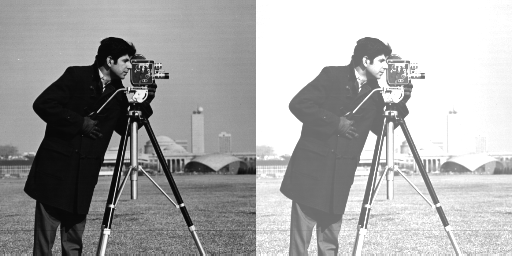

In [37]:
# Display original (left) and brightened (right).
#  Notice the sky becomes pure white: many pixels hit the 255 ceiling, so detail there is LOST.
cv2_imshow(res_img)

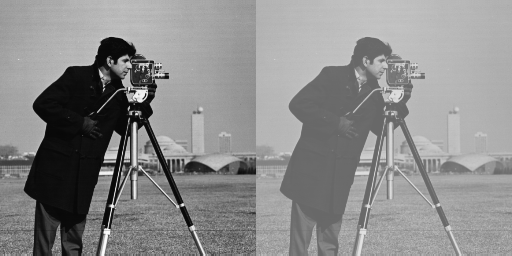

In [38]:
# s = 0.5*r + 100 -> multiply by 0.5 (contrast) and add 100 (brightness).
#  Multiplying by 0.5 squeezes the range 0..255 into 0..127.5, then +100 shifts it to 100..227.5.
#       Result: brighter but FLATTER (lower contrast) image.
img1 = img.astype('float')
img2 = 0.5 * img1 + 100
img2[img2 > 255] = 255
res_img = np.hstack((img1, img2))
cv2_imshow(res_img)

In [39]:
# Scale pixels from 0..255 to 0..1.
#  Many formulas (and the log below) are easier to read on the 0..1 scale.
imgn = img1 / 255  # scaled

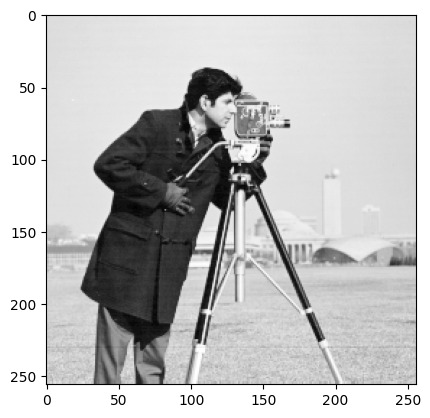

In [40]:
# Take the natural log of the scaled image and display it (original faculty cell).
#  Log makes dark details more visible.
img_log = np.log(imgn)
#cv2_imshow(img_log)
#res_img=np.hstack((img1,img2,img_log))
plt.imshow(img_log, cmap='gray')

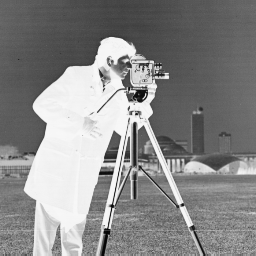

In [41]:
# Create the negative image: new = 255 - old.
#  Black (0) becomes white (255) and white becomes black. Radiologists often view X-rays this way.
img3 = 255 - img1
cv2_imshow(img3)

<a name="s5" id="s5"></a>

## 5. Histograms and histogram equalization

[⬆ Back to top](#top)

**What this section does:** A **histogram** counts how many pixels have each value 0–255. A *low-contrast* image uses only a narrow
band of values (here only 92–141). **Histogram equalization** spreads these values over the full 0–255 range,
so the image gets much more contrast.

In [42]:
# Histogram Equalization = spread values automatically;
# Histogram Specification = match a target histogram;
# Adaptive Histogram equalization (CLAHE) = equalize small tiles separately (better for medical images).

In [43]:
# Read the low-contrast fruit basket image directly as grayscale (flag 0).
# Flag 0 = cv2.IMREAD_GRAYSCALE -> we get a 2-D array straight away (no need to slice a channel).
fruit = cv2.imread(IMG_DIR + 'low_contrast_fruit_basket.jpg', 0)

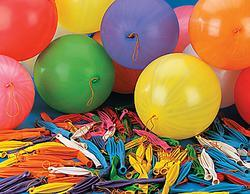

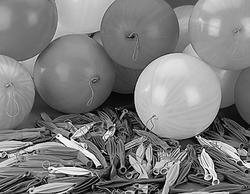

In [44]:
# In case you are wondering what the 0 flag in cv2.imread() does

temp_img = cv2.imread(IMG_DIR + 'ballons.bmp') # Without 0 flag --> Stays colored
cv2_imshow(temp_img)

temp_img = cv2.imread(IMG_DIR + 'ballons.bmp', 0) # With 0 flag --> Becomes greyscale
cv2_imshow(temp_img)

In [45]:
# Check the size of the image.
#  131 x 131 pixels, 1 channel.
fruit.shape

(131, 131)

In [46]:
# Find the darkest and brightest pixel values.
#  92..141 is a very narrow band of the possible 0..255 -> the image looks "washed out" (low contrast).
fruit.min(), fruit.max()

(np.uint8(92), np.uint8(141))

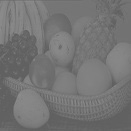

In [47]:
# Notice how grey and dull it looks — this is what a narrow value range looks like.
cv2_imshow(fruit)

In [48]:
fruit.ravel()

array([113, 117, 118, ...,  97,  97,  97], dtype=uint8)

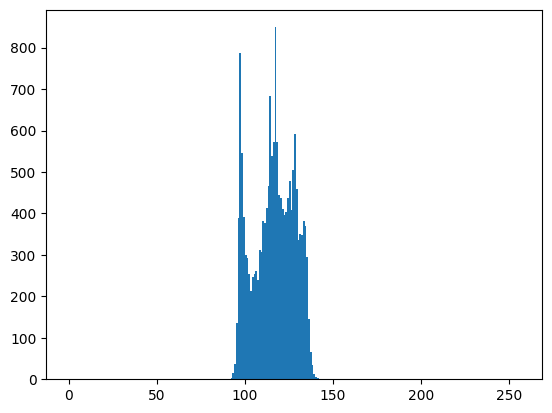

In [49]:
# Plot the histogram of the fruit image (256 bins, one per grey level).
# All the bars sit between ~92 and ~141 — a picture of the "low contrast" problem.
plt.hist(fruit.ravel(), bins=256, range=(0, 256))
plt.show()

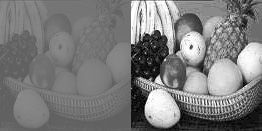

In [50]:
# Apply histogram equalization and show before (left) / after (right).
#  cv2.equalizeHist maps each value using the cumulative histogram (CDF):
#       new = round( (CDF(r) - CDF_min) / (N - CDF_min) * 255 ), so the values spread over 0..255.
img_eq = cv2.equalizeHist(fruit)
res = np.hstack((fruit, img_eq))
cv2_imshow(res)

Low contrast means all pixels are bunched into a narrow brightness band. Your eye struggles to tell nearby tones apart because they’re almost the same value. With equalization, you spread the pixel values so they use the full 0–255 range instead of a narrow band. Wherever many pixels were bunched into nearly the same intensity earlier, the formula pushes those intensities far apart, so tones that looked almost identical now become clearly different — and that’s what raises the contrast, thanks to the above formula.

**Note on CDF calculation**

Let me use the same tiny image:

$$\begin{bmatrix} 3 & 4 & 4 \\ 5 & 4 & 3 \end{bmatrix}$$
Step 1 — First get the histogram (the counts)

Count how many pixels have each brightness value:

- Brightness 3 appears 2 times (top-left, bottom-right)
- Brightness 4 appears 3 times
- Brightness 5 appears 1 time


Step 2 — CDF(r) = add the counts up, left to right

CDF = Cumulative (running) total. For each brightness, you add its own count plus everything **before** it.

$$\text{CDF}(3) = 2 \quad \text{(just the count at 3)}$$
$$\text{CDF}(4) = 2 + 3 = 5 \quad \text{(count at 3, plus count at 4)}$$
$$\text{CDF}(5) = 2 + 3 + 1 = 6 \quad \text{(everything so far)}$$

**So CDF(r) literally means: “how many pixels are this intense or lower?”**

CDF(4) = 5 → five pixels are with intensity 4 or less. The last CDF always equals $N$ (total pixels = 6).


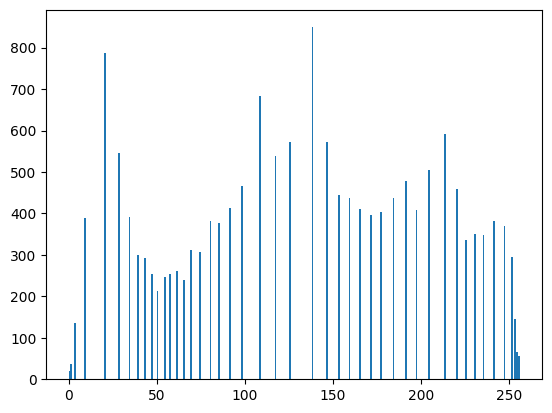

In [51]:
# Plot the histogram of the equalized image.
#  The bars now cover 0..255 -> contrast is much higher.
plt.hist(img_eq.ravel(), bins=256, range=(0, 256))
plt.show()

<a name="s6" id="s6"></a>

## 6. Spatial filtering with kernels (convolution)

[⬆ Back to top](#top)

**What this section does:** Now each new pixel depends on its **neighbours** too. We slide a small matrix called a **kernel / mask**
over the image (this is convolution, Slides 13–17):
- a **3×3 mean (average) kernel** — every weight is 1/9 — removes noise (blurs);
- a **Laplacian-style kernel** (centre 8, neighbours −1) — highlights edges and small bright spots (nodules).

In [52]:
# Read the noisy lung image as grayscale.
# We will remove its "salt-and-pepper"/grainy noise with an averaging filter.
lung = cv2.imread(IMG_DIR + 'noisy_lung.jpg', 0)

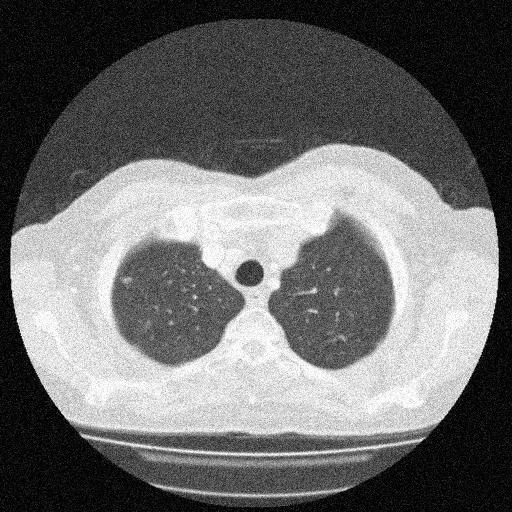

In [53]:
# Look at the grainy texture first so the improvement is visible later.
cv2_imshow(lung)

In [54]:
lung.shape

(512, 512)

In [55]:
print(lung)

[[ 1 14 33 ... 11 15 23]
 [24  7 11 ...  8 32  0]
 [ 6  0  5 ...  1  2 14]
 ...
 [ 0  4  1 ...  2 16 20]
 [15  0 15 ...  3 17 13]
 [ 5  0 11 ...  8 16  2]]


In [56]:
# Build a 3x3 mean kernel (all weights = 1/9) and apply it with cv2.filter2D.
#  Each output pixel = average of the 3x3 neighbourhood -> random noise gets averaged away.
#       ddepth = -1 means "output has the same data type as the input" (uint8).
mask = np.ones((3, 3), dtype='float') / 9
print(mask)
filt = cv2.filter2D(lung, -1, mask)
print(filt)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
[[12 15 16 ... 20 14 20]
 [ 8 11 15 ... 13 12 15]
 [ 9 10  9 ... 11 11 13]
 ...
 [ 4  5  8 ...  7  8 11]
 [ 3  6  7 ... 12 11 15]
 [ 4  8  9 ... 12 10 14]]


In [57]:
# Hand calculation of the filter performed by cv2.filter2D() using 3x3 mask of 1/9

# Pixel 2,2 is surrounded from (1,1) to (3,3) --> 9 values
print(filt[2][2])
print(lung[1:4, 1:4])
round(sum(sum(lung[1:4, 1:4]))/9)

9
[[ 7 11 16]
 [ 0  5 22]
 [13  9  1]]


9

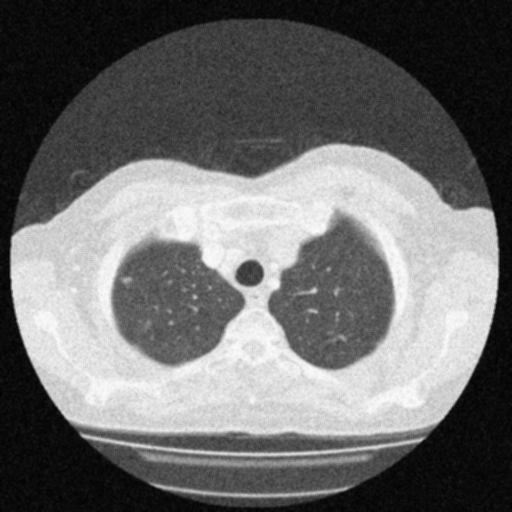

In [58]:
# Noise is reduced, but the image is also slightly blurred — the price of averaging.
cv2_imshow(filt)

**Laplacian filter**

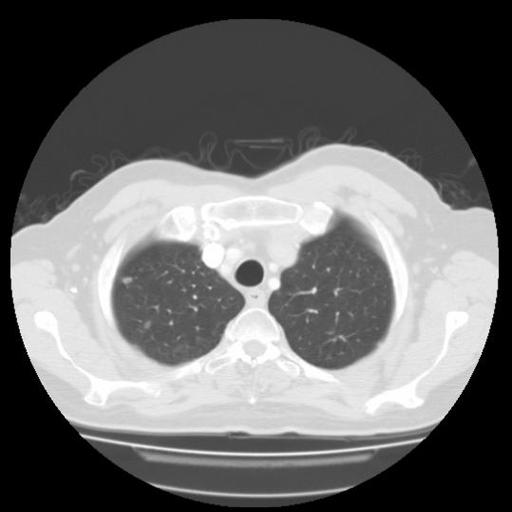

In [59]:
# Read and show a lung image that contains nodules (small round spots).
#  We want to make these small bright spots stand out.
lung1 = cv2.imread(IMG_DIR + '3_nod.jpg', 0)
cv2_imshow(lung1)

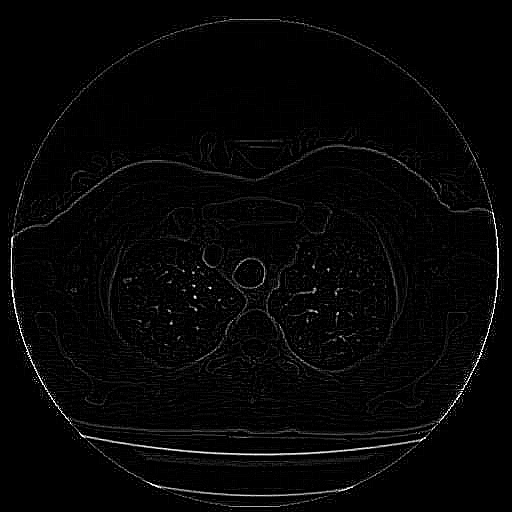

In [60]:
# Apply a Laplacian-style kernel [[-1,-1,-1],[-1,8,-1],[-1,-1,-1]].
#  The weights add up to 0 -> flat areas give 0 (black); places where the centre differs from
#       its neighbours (edges, nodules) give a large value -> they light up.
#       Because the output is uint8, negative results are clipped to 0 (only one side of each edge is shown).
mask = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
filt = cv2.filter2D(lung1, -1, mask)
cv2_imshow(filt)

<a name="s7" id="s7"></a>

## 7. Segmentation by thresholding

[⬆ Back to top](#top)

**What this section does:** **Segmentation** = separating the object of interest (the tumour) from the background.
The simplest way: pick a threshold $T$; pixels $> T$ become white (255 = object), the rest black (0).
We choose $T = 140$ by looking at the histogram.

In [61]:
# Read the MRI image with a tumour (grayscale).
#  This is the image we will segment and measure.
img = cv2.imread(IMG_DIR + 'mri_tumor1.jpg', 0)

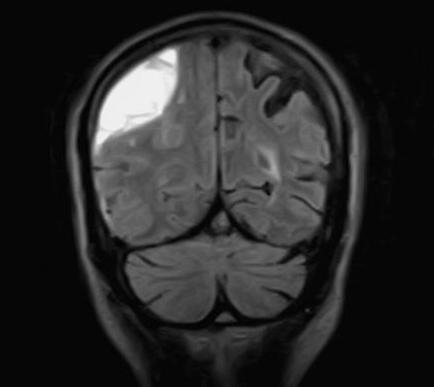

In [62]:
# Display the MRI image.
#  The tumour is the bright region — brighter than most of the brain tissue.
cv2_imshow(img)

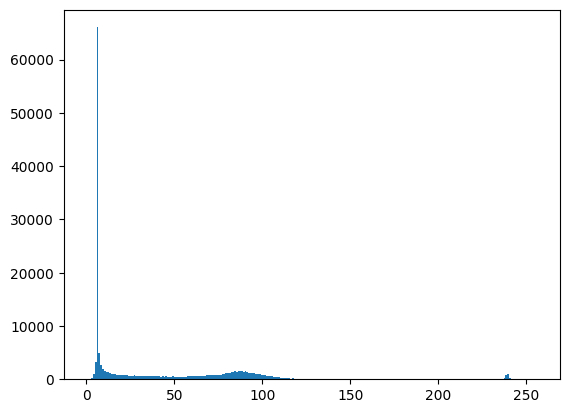

In [63]:
# Plot the histogram of the MRI image.
#  Helps us choose a threshold: the tumour pixels are among the brightest values (right side).
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.show()

# Usually tumor at its core is pretty bright, but can have somewhat-dimmer edges
# The plot below shows a spike at the start (close to 5) suggesting dark pixels (from brain's scan)
# and the very end (close to 240) has a small bump of white pixels. We need to select
# a threshold that not only picks the tumor's core but also the edges or extent/ range of
# of the tumor, safe bet is 140  or 150

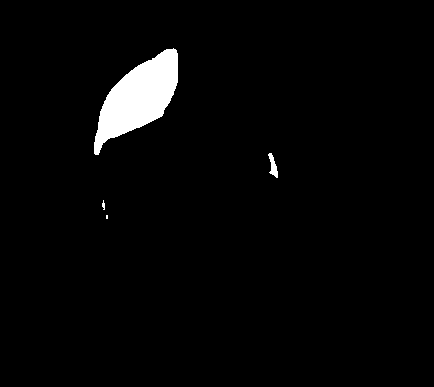

In [64]:
# Threshold at 140 -> binary image (only 0 and 255).
#  Pixels brighter than 140 are "probably tumour" (white); everything else is background (black).
#       We re-read the image first so the original values are used.
img = cv2.imread(IMG_DIR + 'mri_tumor1.jpg', 0)
img[img > 140] = 255
img[img <= 140] = 0
cv2_imshow(img)

<a name="s8" id="s8"></a>

## 8. Morphological operations (opening)

[⬆ Back to top](#top)

**What this section does:** Thresholding also kept a few small bright specks that are **not** tumour. *Morphological opening*
(= **erosion** then **dilation** with a small shape called a *structuring element*) deletes objects smaller
than the structuring element but keeps the big tumour almost unchanged.

In [65]:
# List of common morphological operations (comment only).
#  Dilation grows white regions, erosion shrinks them; opening = erosion then dilation; closing = dilation then erosion.
#Morphological Operations
#Dilation, Erosion, clear border, skeletonization, thickening, thinning, areaopen, closing

Here’s a tiny binary image. White = 1, black = 0. Structuring element $B$ is a $3\times3$ square (all ones).

Original image $A$ — a $3\times3$ blob on the left, plus a single stray speck on the right:

$$A = \begin{bmatrix} 0&0&0&0&0&0&0 \\ 0&1&1&1&0&0&0 \\ 0&1&1&1&0&0&1 \\ 0&1&1&1&0&0&0 \\ 0&0&0&0&0&0&0 \end{bmatrix}$$

Step 1 — Erosion $(A \ominus B)$: a pixel stays 1 only if the full $3\times3$ square fits inside the white region when centered on it. [Minkowski subtraction]

The blob’s center pixel (row 2, col 2) has all 8 neighbours white → the square fits → stays 1.
Every other white pixel in the blob has at least one black neighbour → square doesn’t fit → becomes 0.
The stray speck has black all around it → becomes 0.
$$A \ominus B = \begin{bmatrix} 0&0&0&0&0&0&0 \\ 0&0&0&0&0&0&0 \\ 0&0&1&0&0&0&0 \\ 0&0&0&0&0&0&0 \\ 0&0&0&0&0&0&0 \end{bmatrix}$$

The blob shrank to one pixel; the speck is gone.

Step 2 — Dilation $(\ldots \oplus B)$: turn a pixel 1 if the $3\times3$ square centered on it touches any white pixel. Only that one surviving center pixel is white, so its $3\times3$ neighbourhood lights up [Minkowski addition]:

$$(A \ominus B) \oplus B = \begin{bmatrix} 0&0&0&0&0&0&0 \\ 0&1&1&1&0&0&0 \\ 0&1&1&1&0&0&0 \\ 0&1&1&1&0&0&0 \\ 0&0&0&0&0&0&0 \end{bmatrix}$$

Result: the $3\times3$ blob is back to its original shape, and the stray speck is permanently removed. That’s opening — $A \circ B = (A \ominus B) \oplus B$ — removing small junk while leaving the large object intact.

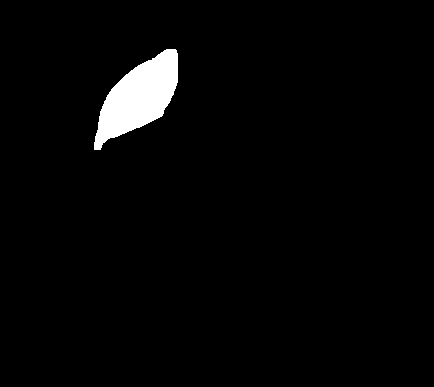

In [66]:
# Create a 7x7 rectangular structuring element and apply morphological OPENING.
#  Erosion (7x7) wipes out any white blob that cannot fully contain a 7x7 square (the small specks);
#       dilation then grows the surviving tumour back to roughly its original size.
se1 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
mask = cv2.morphologyEx(img, cv2.MORPH_OPEN, se1)
cv2_imshow(mask)

<a name="s9" id="s9"></a>

## 9. Manual feature extraction (to solve it via an ML problem)

[⬆ Back to top](#top)

**What this section does:** We now describe the tumour with numbers (**features**): area, maximum height/width, an elongation ratio,
perimeter, centroid (centre point), contour area, convex-hull area and the radius of the smallest enclosing circle.
This is **manual feature extraction**

In [67]:
# Groups of hand-made/ manual features
# Shape = size/outline
# Texture = how intensities vary inside
# Colour = colour statistics.
# Extract these feature manually: Shape feat, Texture feat, color feat

In [68]:
# Area = number of white (non-zero) pixels in the mask.
#  (mask != 0) gives True/False for each pixel; .sum() counts the Trues -> area in pixels.
# Area of RoI = Number of pixels forming that region of interest (RoI)
ar = (mask != 0).sum()
ar

np.int64(4448)

In [69]:
# Max height = the largest count of white pixels in any COLUMN; max width = largest count in any ROW.
#  sum(axis=0) adds down each column, sum(axis=1) adds across each row; .max() picks the biggest.
# count the number of non zero pixels in each column in the image and pick the max count.
max_h = (mask != 0).sum(axis=0).max()
print(max_h)
max_w = (mask != 0).sum(axis=1).max()
print(max_w)

# the tumour is roughly as tall as it is wide

65
66


In [70]:
# Ratio of max height to max width
# Close to 1 -> roughly round; far from 1 -> elongated.
# eccentricity
ecc = max_h / max_w
ecc

# this may be called as ASPECT RATIO, not true eccentricity. True eccentricity of an ellipse is
# e = sqrt(1 - (b/a)^2), where a, b are the semi-major/semi-minor axes (0 = circle, near 1 = very stretched).

np.float64(0.9848484848484849)

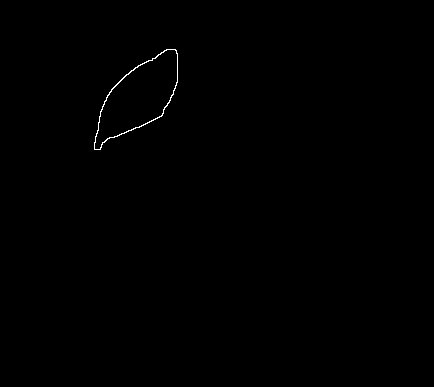

np.int64(366)

In [71]:
# Perimeter = number of edge pixels found with the Laplacian kernel.
#  Inside the tumour (all 255) and in the background (all 0) the kernel gives 0;
#       only the boundary pixels give a non-zero response -> counting them approximates the perimeter.
# 🔧 Fixed: np.matrix replaced by np.array (same result).
# Perimeter
m = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
edge = cv2.filter2D(mask, -1, m)
cv2_imshow(edge)
peri = (edge != 0).sum()
peri

In [72]:
# Centroid (centre of mass) using image moments: x = m10/m00, y = m01/m00.
#  m00 = total "mass" (sum of pixel values), m10 = sum of x*value, m01 = sum of y*value.
#       Dividing gives the average x and average y position of the white pixels = the centre point.
#centroid
mom = cv2.moments(mask)
x_cent = np.round(mom['m10'] / mom['m00'])
y_cent = np.round(mom['m01'] / mom['m00'])
print(x_cent, y_cent)

138.0 97.0


In [73]:
# Find the outer boundary (contour) of every white object.
#  RETR_EXTERNAL = only outer outlines; CHAIN_APPROX_NONE = keep every boundary point.
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

In [74]:
# Pick the tumour's contour.
#  🔧 Fixed: the original used contours[0] (the first one found). If more than one blob survives,
#       that may not be the tumour, so we take the contour with the LARGEST area (same result here: only one blob).
cnt = max(contours, key=cv2.contourArea)

In [75]:
# Area enclosed by the contour (polygon area).
#  Slightly smaller than the pixel count (4448) because the outline runs through pixel CENTRES,
#       so half of each boundary pixel is outside the polygon.
cnt_ar = cv2.contourArea(cnt)
cnt_ar

4315.5

In [76]:
# Convex hull = the tightest "rubber band" around the contour; compute its area.
#  Comparing hull area with contour area tells how irregular the outline is:
#       solidity = contour area / hull area (close to 1 = smooth, convex shape).
hull = cv2.convexHull(cnt)
hull_ar = cv2.contourArea(hull)
hull_ar

4562.5

In [77]:
# Radius of the smallest circle that fully encloses the tumour.
#  Another size measure; a radius of ~64 px matches the ~65 px height/width found above.
(x, y), rad = cv2.minEnclosingCircle(cnt)
rad

64.3448715209961

In [78]:
# ➕ Added — TRUE eccentricity from an ellipse fitted to the contour.
#  Shows the textbook definition e = sqrt(1 - (b/a)^2) next to the simple height/width ratio above.
#       Result here: ratio = 0.985 ("looks round") but e = 0.90 ("clearly elongated") -> the tumour is a
#       TILTED, leaf-like shape. A height/width count cannot see tilt; the fitted ellipse can.
(cx, cy), (d1, d2), angle = cv2.fitEllipse(cnt)      # d1, d2 = full axis lengths
a, b = max(d1, d2) / 2, min(d1, d2) / 2               # semi-major, semi-minor axes
print('semi-axes a, b =', round(a, 1), round(b, 1))
print('true eccentricity =', round(np.sqrt(1 - (b / a) ** 2), 3), '| height/width ratio =', round(ecc, 3))

semi-axes a, b = 57.7 25.1
true eccentricity = 0.901 | height/width ratio = 0.985


<a name="s10" id="s10"></a>

## 10. Texture (intensity) features of the tumour

[⬆ Back to top](#top)

**What this section does:** Shape tells *how big / what outline*; **texture** tells *what the inside looks like*. We cut the tumour out of
the original MRI using the mask and compute the **mean**, **standard deviation** and **skewness** of its pixel values.

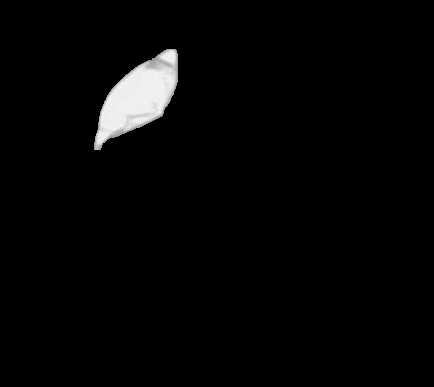

In [79]:
# Re-read the original MRI and keep only the tumour pixels (multiply by a 0/1 mask).
#  mask has values 0/255; dividing by 255 makes it 0/1, so  image x mask  keeps tumour pixels and zeros the rest.
# store the 0/1 mask in a NEW variable (mask01). The original did mask = mask/255, which breaks
#    the cell if it is run a second time (mask would become 0/0.0039...).
# Texture features
#mean, var, std, skew,
img = cv2.imread(IMG_DIR + 'mri_tumor1.jpg', 0)
mask01 = mask / 255
tum = img * mask01
cv2_imshow(tum)

In [80]:
# Mean intensity of the tumour pixels.
#  tum[tum != 0] keeps only tumour pixels (background zeros are ignored). Mean = average brightness.
me = np.mean(tum[tum != 0])
me

np.float64(221.9878597122302)

In [81]:
# Standard deviation of the tumour pixels.
#  Small SD = uniform inside; large SD = patchy/heterogeneous inside.
sd = np.std(tum[tum != 0])
sd

np.float64(25.997005155860634)

In [82]:
# Skewness of the tumour pixel values.
#  Negative skew (here about -1.56) = a long tail towards DARK values: most pixels are bright, a few are much darker.
import scipy.stats as stats
sk = stats.skew(tum[tum != 0])
sk

np.float64(-1.5558808873285652)

<a name="s11" id="s11"></a>

## 11. Build the feature vector → a dataset for ML

[⬆ Back to top](#top)

**What this section does:** We collect all 13 numbers into one **feature vector**. Do this for 1,000 images and you get a
1000 × 13 table — exactly the kind of tabular data a classic ML model (logistic regression, random forest…) can learn from.

In [83]:
# Put the 13 features into one NumPy array.
#  One image -> one row of numbers (a feature vector).
feat = np.array([ar, max_h, max_w, ecc, peri, x_cent, y_cent, cnt_ar, hull_ar, rad, me, sd, sk])

In [84]:
# Convert the array to a pandas DataFrame.
#  A table is easier to read.
feat = pd.DataFrame(feat,
                    index=['area', 'max_height', 'max_width', 'height/width', 'perimeter',
                           'centroid_x', 'centroid_y', 'contour_area', 'hull_area',
                           'enclosing_radius', 'mean', 'std', 'skewness'],
                    columns=['value'])

In [85]:
# Display the feature table.
#  These 13 numbers now summarise the whole tumour.
feat

,value
area,4448.000000
max_height,65.000000
max_width,66.000000
height/width,0.984848
perimeter,366.000000
centroid_x,138.000000
centroid_y,97.000000
contour_area,4315.500000
hull_area,4562.500000
enclosing_radius,64.344872


In [86]:
# How this becomes a machine-learning project
# Features (X) come from images, labels (y) come from the radiologist's report -> train any ML classifier.
# Say if u have 1000 images, u can calculate these 13 features for each image and can generate the dataset of size 1000x13
# frame the output column for each image with the help of radiologist report
# With this build any ML model to predict the cancerous nature of tumor

<a name="s12" id="s12"></a>

## 12. Summary and key takeaways

[⬆ Back to top](#top)

- An image is a matrix of numbers (0 = black … 255 = white). Shape = (rows, columns, channels).
- **Point operations** use one pixel at a time (brightness, contrast, log, negative).
- **Histogram equalization** spreads a narrow range of values over 0–255 → more contrast.
- **Kernels / convolution** use the neighbourhood: averaging removes noise, Laplacian-type kernels find edges.
- **Thresholding + morphology** cut out an object (segmentation).
- **Hand-made features** (area, perimeter, mean, skewness…) turn an image into one row of a table.
  The weakness: a human has to *design* every feature → CNNs **learn** the features instead.